# Bandit controller

**Goal:** read a question and choose how much effort the LLM should spend on it.

The LLM is **not** trained or run here. We already recorded 10 answers per question at every effort level, so we can
calculate what each choice would have given.

**The notebook in 8 steps**

| Step | What happens |
|---|---|
| 1 | Settings |
| 2 | Load the recorded answers |
| 3 | Calculate how good each of the 9 plans is for each question |
| 4 | Look at one real question |
| 5 | Build the network |
| 6 | Train **BD-1**: learns from the exact score of every plan |
| 7 | Train **BD-2**: learns by trying one plan at a time |
| 8 | Compare with simply using the same plan for every question |

**The 9 plans.** `M×3` means: run the LLM 3 times at medium effort and take the majority answer.

**The score of a plan** (called *utility*):

$$\text{utility} = \text{accuracy} - \lambda \times \frac{\text{tokens}}{C_{ref}}$$

$\lambda$ says how much we care about saving tokens. $C_{ref}$ is the average cost of one H run on that dataset.

## Step 1. Settings

In [1]:
import itertools, json, math, os, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

# Folders
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "controller_data").is_dir())
DATA = ROOT / "controller_data"
OUTPUT = Path(os.environ.get("BANDIT_OUT", ROOT / "rl_training" / "outputs" / "bandit"))
FIGURES = OUTPUT / "figures" if "BANDIT_OUT" in os.environ else ROOT / "figures" / "bandit"
OUTPUT.mkdir(parents=True, exist_ok=True)

# Keep False until every choice has been made on validation. The test split must be used only once.
RUN_TEST = False

# Experiment
DATASETS = ["gsm8k", "math", "amc23"]
LAMBDAS = [0.02, 0.05, 0.10, 0.25, 0.50]
SEEDS = [0, 1, 2, 3, 4]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Token budget of each effort level, per dataset
BUDGETS = {
    "gsm8k": {"L": 2048, "M": 4096, "H": 16384},
    "math": {"L": 4096, "M": 12288, "H": 16384},
    "amc23": {"L": 12288, "M": 24576, "H": 32768},
}
LEVELS = ["L", "M", "H"]

# The 9 plans: (level, number of runs)
PLANS = [("L", 1), ("L", 3), ("L", 5),
         ("M", 1), ("M", 3), ("M", 5),
         ("H", 1), ("H", 3), ("H", 5)]
PLAN_NAMES = [f"{level}×{runs}" for level, runs in PLANS]

print("Device:", DEVICE)
print("Plans:", PLAN_NAMES)

Device: cuda
Plans: ['L×1', 'L×3', 'L×5', 'M×1', 'M×3', 'M×5', 'H×1', 'H×3', 'H×5']


## How seeds work

A **seed** is a starting number for a random-number generator. The same seed gives the same random choices, so a run can be repeated.

| Seed | Value | How it is made | What it controls |
|---|---|---|---|
| Data split | `2026` | fixed in `prepare_data.py` / `prepare_math.py` | which questions go to train, validation, test |
| LLM recording | one per trace | SHA-256 of `question_id\|sample`, first 8 hex digits as a number | the random sampling of that recorded answer |
| **Training** | `0, 1, 2, 3, 4` | written in `SEEDS` | starting weights, sampled questions, traces and actions |
| Bootstrap | `0` | fixed | the question resampling used for the 95% ranges |

Training the same model with 5 seeds shows how much a result depends on luck.

In [2]:
import hashlib

def recording_seed(question_id, sample):
    return int(hashlib.sha256(f"{question_id}|{sample}".encode()).hexdigest()[:8], 16)

print("Recording seeds of question 'gsm8k-1':", [recording_seed("gsm8k-1", k) for k in range(3)])
torch.manual_seed(0); first = torch.rand(3).tolist()
torch.manual_seed(0); again = torch.rand(3).tolist()
torch.manual_seed(1); other = torch.rand(3).tolist()
print("seed 0:", [round(x, 3) for x in first], "| seed 0 again:", [round(x, 3) for x in again], "| seed 1:", [round(x, 3) for x in other])

Recording seeds of question 'gsm8k-1': [1973596014, 3079404675, 3808998835]
seed 0: [0.496, 0.768, 0.088] | seed 0 again: [0.496, 0.768, 0.088] | seed 1: [0.758, 0.279, 0.403]


## Step 2. Load the recorded answers

For every question we keep a table of **3 levels × 10 recorded answers**: its tokens, whether it is correct, and its
answer group.

**Answer groups.** `7/2`, `3.5` and `\frac{7}{2}` are the same answer, so they must count together in a majority vote.
Groups are built by comparing answers with each other. The correct answer is never used to build them.

In [3]:
sys.path.insert(0, str(ROOT / "generation_math" / "src"))
from grade_math import answer_box, parse, verify


def same_math_answer(a, b):
    """True if Math-Verify finds the two parsed answers equal, in either direction."""
    try:
        return bool(a and b and (verify(a, b) or verify(b, a)))
    except Exception:
        return False


def group_answers(dataset, answers, boxes):
    """Give each answer a group number. An invalid answer (None) gets -1."""
    if dataset == "gsm8k":
        numbers = [None if a is None else float(a) for a in answers]
        group_of = {number: i for i, number in enumerate(sorted({n for n in numbers if n is not None}))}
        return [-1 if n is None else group_of[n] for n in numbers]

    # MATH and AMC: parse each different answer once
    parsed = {}
    for answer, box in zip(answers, boxes):
        if answer is not None and answer not in parsed:
            try:
                parsed[answer] = parse("\\boxed{" + box + "}")
            except Exception:
                parsed[answer] = None

    # Add answers one by one and merge every group they match
    groups = []
    for answer in sorted(parsed):
        matching = [g for g in groups if any(same_math_answer(parsed[answer], parsed[other]) for other in g)]
        groups = [g for g in groups if g not in matching]
        groups.append([answer] + [member for g in matching for member in g])

    group_of = {member: i for i, group in enumerate(groups) for member in group}
    return [-1 if a is None else group_of[a] for a in answers]


def load_split(dataset, split):
    """Load one file, for example MATH train."""
    columns = ["question_id", "sample", "budget", "config", "pred", "valid", "correct", "total_tokens",
               "prompt_tokens", "n_numbers"]
    if dataset != "gsm8k":
        columns.append("answer_text")
    rows = pd.read_csv(DATA / f"{dataset}_{split}_controller.csv", usecols=columns, na_filter=False,
                       dtype={"question_id": str, "pred": str})

    # Keep only the 3 levels of this dataset
    rows = rows[(rows.config == "t0.6_pp1.5") & rows.budget.isin(BUDGETS[dataset].values())].copy()

    # Sort the rows so they can be reshaped into (questions, 3 levels, 10 answers)
    question_ids = [str(q) for q in np.load(DATA / "embeddings" / f"{dataset}_{split}_q_ids.npy", allow_pickle=True)]
    position = {q: i for i, q in enumerate(question_ids)}
    rows["position"] = rows.question_id.map(position)
    rows = rows.sort_values(["position", "budget", "sample"])
    n = len(question_ids)
    shape = (n, 3, 10)
    assert len(rows) == n * 3 * 10

    valid = rows.valid.to_numpy().astype(bool)
    answers = [p if v else None for p, v in zip(rows.pred, valid)]
    boxes = [answer_box(t) if v else None for t, v in zip(rows.answer_text, valid)] if dataset != "gsm8k" else answers

    groups = []
    for q in range(n):
        start, end = q * 30, (q + 1) * 30
        groups += group_answers(dataset, answers[start:end], boxes[start:end])

    return {
        "ids": question_ids,
        "embedding": np.load(DATA / "embeddings" / f"{dataset}_{split}_q_64.npy").astype(np.float32),
        "prompt_tokens": rows.prompt_tokens.to_numpy(float).reshape(shape)[:, 0, 0],
        "numbers": rows.n_numbers.to_numpy(float).reshape(shape)[:, 0, 0],
        "tokens": rows.total_tokens.to_numpy(float).reshape(shape),
        "correct": (rows.correct.to_numpy() * valid).reshape(shape),
        "groups": np.array(groups).reshape(shape),
        "answers": np.array(answers, dtype=object).reshape(shape),
    }


splits = ["train", "val"] + (["test"] if RUN_TEST else [])
recorded = {(dataset, split): load_split(dataset, split) for dataset in DATASETS for split in splits}

for (dataset, split), d in recorded.items():
    print(f"{dataset:6} {split:5} {len(d['ids']):4} questions, table shape {d['tokens'].shape}")

gsm8k  train  919 questions, table shape (919, 3, 10)
gsm8k  val    200 questions, table shape (200, 3, 10)
math   train  400 questions, table shape (400, 3, 10)
math   val     99 questions, table shape (99, 3, 10)
amc23  train   24 questions, table shape (24, 3, 10)
amc23  val      8 questions, table shape (8, 3, 10)


## Step 3. How good is each plan for each question?

Take `M×3`. A question has 10 recorded answers at level M, so there are 120 possible sets of 3. We score **all 120**:

1. Find the largest answer group in the set.
2. If it is correct, the set scores 1. If it is wrong, it scores 0.
3. If `m` groups tie, the set scores the average over those `m` groups, as if one were picked at random.

The plan's **accuracy** is the mean score of all its sets. Its **cost** is `runs × mean tokens at that level`.

In [4]:
ALL_DRAWS = {runs: list(itertools.combinations(range(10), runs)) for runs in (1, 3, 5)}


def score_draw(groups, correct):
    """Score one set of answers with a majority vote."""
    votes = {}
    for group, is_correct in zip(groups, correct):
        if group >= 0:                                # skip invalid answers
            votes.setdefault(group, []).append(is_correct)
    if not votes:
        return 0.0
    largest = max(len(v) for v in votes.values())
    winners = [v for v in votes.values() if len(v) == largest]
    return sum(sum(v) / len(v) for v in winners) / len(winners)


def score_plan(groups, correct, runs):
    """Score of every possible set of `runs` answers for one question at one level."""
    groups, correct = groups.tolist(), correct.tolist()
    return [score_draw([groups[i] for i in draw], [correct[i] for i in draw]) for draw in ALL_DRAWS[runs]]


# Constants measured on train only
C_REF = {d: recorded[d, "train"]["tokens"][:, LEVELS.index("H")].mean() for d in DATASETS}
PROMPT_P95 = np.percentile(np.concatenate([recorded[d, "train"]["prompt_tokens"] for d in DATASETS]), 95)
NUMBERS_P95 = np.percentile(np.concatenate([recorded[d, "train"]["numbers"] for d in DATASETS]), 95)

# How often each dataset is picked in training: proportional to the square root of its size
train_sizes = np.array([len(recorded[d, "train"]["ids"]) for d in DATASETS])
DATASET_SHARE = np.sqrt(train_sizes) / np.sqrt(train_sizes).sum()


def build_table(split):
    """Join the three datasets and compute accuracy and cost of the 9 plans."""
    parts = [recorded[d, split] for d in DATASETS]
    joined = {key: np.concatenate([p[key] for p in parts]) for key in
              ("embedding", "prompt_tokens", "numbers", "tokens", "correct", "groups", "answers")}
    n = len(joined["tokens"])
    dataset_id = np.concatenate([[i] * len(p["ids"]) for i, p in enumerate(parts)])
    c_ref = np.array([C_REF[DATASETS[i]] for i in dataset_id])

    draw_scores, accuracy, tokens = [], np.zeros((n, 9)), np.zeros((n, 9))
    for p, (level, runs) in enumerate(PLANS):
        l = LEVELS.index(level)
        scores = np.array([score_plan(joined["groups"][q, l], joined["correct"][q, l], runs) for q in range(n)])
        draw_scores.append(scores)
        accuracy[:, p] = scores.mean(axis=1)
        tokens[:, p] = runs * joined["tokens"][np.arange(n), l].mean(axis=1)

    features = np.c_[np.minimum(joined["prompt_tokens"] / PROMPT_P95, 1), np.minimum(joined["numbers"] / NUMBERS_P95, 1)]
    return {**joined, "dataset": dataset_id, "c_ref": c_ref, "draw_scores": draw_scores,
            "accuracy": accuracy, "plan_tokens": tokens, "cost": tokens / c_ref[:, None],
            "x_embedding": torch.tensor(joined["embedding"], device=DEVICE),
            "x_scalars": torch.tensor(features, dtype=torch.float32, device=DEVICE)}


tables = {split: build_table(split) for split in splits}
train, val = tables["train"], tables["val"]

print("C_ref:", {d: round(v) for d, v in C_REF.items()})
print("Dataset shares:", dict(zip(DATASETS, DATASET_SHARE.round(3))))

C_ref: {'gsm8k': 6872, 'math': 8740, 'amc23': 13004}
Dataset shares: {'gsm8k': np.float64(0.549), 'math': np.float64(0.362), 'amc23': np.float64(0.089)}


### Check: do the values match `BANDIT.md`?

For each dataset and λ, we look for the best single plan on train. The notebook stops if a value differs from the document.

In [5]:
EXPECTED = {"gsm8k": [.883, .861, .837, .778, .710],
            "math": [.810, .780, .730, .632, .528],
            "amc23": [.576, .546, .497, .367, .192]}

rows = []
for d, dataset in enumerate(DATASETS):
    mask = train["dataset"] == d
    for lam, expected in zip(LAMBDAS, EXPECTED[dataset]):
        plan_utility = (train["accuracy"][mask] - lam * train["cost"][mask]).mean(axis=0)
        rows.append({"dataset": dataset, "λ": lam, "best plan": PLAN_NAMES[plan_utility.argmax()],
                     "utility": round(plan_utility.max(), 3), "in BANDIT.md": expected})
check = pd.DataFrame(rows)
assert (check["utility"] - check["in BANDIT.md"]).abs().max() <= 0.0011
print(check.to_string(index=False))

dataset    λ best plan  utility  in BANDIT.md
  gsm8k 0.02       H×1    0.883         0.883
  gsm8k 0.05       M×1    0.861         0.861
  gsm8k 0.10       M×1    0.837         0.837
  gsm8k 0.25       L×1    0.778         0.778
  gsm8k 0.50       L×1    0.710         0.710
   math 0.02       H×1    0.810         0.810
   math 0.05       H×1    0.780         0.780
   math 0.10       H×1    0.730         0.730
   math 0.25       L×1    0.632         0.632
   math 0.50       L×1    0.528         0.528
  amc23 0.02       H×1    0.576         0.576
  amc23 0.05       H×1    0.546         0.546
  amc23 0.10       M×1    0.497         0.497
  amc23 0.25       L×1    0.367         0.367
  amc23 0.50       L×1    0.192         0.192


## Step 4. Look at one real question

This is what the recordings look like for one MATH question, and how its 9 plans are scored at λ = 0.10.

In [6]:
example = len(recorded["gsm8k", "train"]["ids"]) + 5     # the 6th MATH train question
level = LEVELS.index("M")
print("Question:", recorded["math", "train"]["ids"][5])
print("\nThe 10 recorded answers at level M:")
for i in range(10):
    mark = "right" if train["correct"][example, level, i] else "wrong"
    print(f"  trace {i}: {str(train['answers'][example, level, i]):20} {mark:6} {int(train['tokens'][example, level, i]):6} tokens")

lam = 0.10
one_question = pd.DataFrame({"plan": PLAN_NAMES,
                             "accuracy": train["accuracy"][example].round(3),
                             "cost": train["cost"][example].round(3),
                             "utility": (train["accuracy"][example] - lam * train["cost"][example]).round(3)})
print("\nPlans for this question at λ = 0.10:")
print(one_question.to_string(index=False))
print("\nBest plan for this question:", PLAN_NAMES[one_question.utility.argmax()])

Question: math-train-prealgebra-408

The 10 recorded answers at level M:
  trace 0: 25                   right    1460 tokens
  trace 1: 25                   right    1435 tokens
  trace 2: 25                   right     743 tokens
  trace 3: 25                   right    3794 tokens
  trace 4: 25                   right     589 tokens
  trace 5: 25                   right    1461 tokens
  trace 6: 25                   right    1097 tokens
  trace 7: 25                   right    1099 tokens
  trace 8: 25                   right     941 tokens
  trace 9: 25                   right    1411 tokens

Plans for this question at λ = 0.10:
plan  accuracy  cost  utility
 L×1       1.0 0.161    0.984
 L×3       1.0 0.482    0.952
 L×5       1.0 0.803    0.920
 M×1       1.0 0.161    0.984
 M×3       1.0 0.482    0.952
 M×5       1.0 0.803    0.920
 H×1       1.0 0.161    0.984
 H×3       1.0 0.482    0.952
 H×5       1.0 0.803    0.920

Best plan for this question: L×1


## Step 5. The network

| Step | Layer | Size |
|---|---|---|
| 1 | Compress the question | 64 → 32 |
| 2 | Add 2 numbers: question length, count of numbers | 32 + 2 = 34 |
| 3 | Hidden layer, with dropout | 34 → 64 |
| 4 | Hidden layer | 64 → 64 |
| 5 | Output | 18 for BD-1, 10 for BD-2 |

- **BD-1 outputs 22 numbers:** the accuracy and the cost of each of the 9 plans.
- **BD-2 outputs 10 numbers:** a preference for each plan, plus its expected reward.

In [7]:
class BanditNetwork(nn.Module):
    def __init__(self, n_outputs):
        super().__init__()
        self.question = nn.Sequential(nn.Linear(64, 32), nn.ReLU())
        self.hidden = nn.Sequential(nn.Linear(34, 64), nn.ReLU(), nn.Dropout(0.1),
                                    nn.Linear(64, 64), nn.ReLU())
        self.output = nn.Linear(64, n_outputs)

    def forward(self, embedding, scalars):
        question = self.question(embedding)
        return self.output(self.hidden(torch.cat([question, scalars], dim=1)))


print("BD-1 parameters:", sum(p.numel() for p in BanditNetwork(18).parameters()))
assert sum(p.numel() for p in BanditNetwork(18).parameters()) == 9650


# Choosing training questions: first a dataset, then a question inside it
first_index = np.r_[0, train_sizes.cumsum()[:-1]]

def sample_questions(batch_size, rng):
    chosen_dataset = rng.choice(3, size=batch_size, p=DATASET_SHARE)
    return first_index[chosen_dataset] + (rng.random(batch_size) * train_sizes[chosen_dataset]).astype(int)


# Scoring helpers
def plan_utility(table, plans, lam):
    """Utility of the chosen plan for each question."""
    q = np.arange(len(plans))
    return table["accuracy"][q, plans] - lam * table["cost"][q, plans]


def weighted_mean(table, values):
    """Mean over the datasets, using the same shares as training."""
    return sum(DATASET_SHARE[d] * values[table["dataset"] == d].mean() for d in range(3))

BD-1 parameters: 9650


## Step 6. BD-1: learn from the exact scores

BD-1 predicts the accuracy and the cost of all 9 plans. To choose, it picks the plan with the highest
`accuracy − λ × cost`, so **one model works for every λ**.

Each epoch: train on batches, measure the score on validation, and keep the best model. Training stops after 30 epochs
with no improvement.

In [8]:
@torch.no_grad()
def bd1_choose(model, table, lam):
    model.eval()
    output = model(table["x_embedding"], table["x_scalars"])
    predicted_accuracy, predicted_cost = torch.sigmoid(output[:, :9]), output[:, 9:]
    return (predicted_accuracy - lam * predicted_cost).argmax(dim=1).cpu().numpy()


def train_bd1(seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = BanditNetwork(18).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

    target_accuracy = torch.tensor(train["accuracy"], dtype=torch.float32, device=DEVICE)
    target_cost = torch.tensor(train["cost"], dtype=torch.float32, device=DEVICE)
    batches_per_epoch = math.ceil(len(train["dataset"]) / 256)

    best_score, best_weights, epochs_without_gain, history = -np.inf, None, 0, []
    for epoch in range(1, 301):
        model.train()
        for _ in range(batches_per_epoch):
            batch = torch.tensor(sample_questions(256, rng), device=DEVICE)
            output = model(train["x_embedding"][batch], train["x_scalars"][batch])
            loss = F.binary_cross_entropy_with_logits(output[:, :9], target_accuracy[batch]) \
                 + F.mse_loss(output[:, 9:], target_cost[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Validation score: averaged over the five λ values
        score = np.mean([weighted_mean(val, plan_utility(val, bd1_choose(model, val, lam), lam)) for lam in LAMBDAS])
        history.append(score)
        if score > best_score + 1e-5:
            best_score, epochs_without_gain = score, 0
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            epochs_without_gain += 1
            if epochs_without_gain == 30:
                break

    model.load_state_dict(best_weights)
    torch.save(best_weights, OUTPUT / f"bd1_seed{seed}.pt")
    print(f"BD-1 seed {seed}: stopped at epoch {epoch}, best validation utility {best_score:.4f}")
    return model


def get_bd1(seed):
    path = OUTPUT / f"bd1_seed{seed}.pt"
    if not path.exists():
        return train_bd1(seed)
    model = BanditNetwork(18).to(DEVICE)
    model.load_state_dict(torch.load(path, map_location=DEVICE))
    return model


bd1_models = {seed: get_bd1(seed) for seed in SEEDS}

## Step 7. BD-2: learn by trying

BD-2 does not see the table of scores. For each question in a batch:

1. Pick one plan at random, according to its current preferences.
2. Pick one random set of recorded answers for that plan.
3. Receive one reward: `1 if correct, else 0`, minus `λ × tokens / C_ref`.
4. If the reward beats what it expected, prefer that plan more. If not, prefer it less.

The reward depends on λ, so it needs **one model per λ**.

In [9]:
@torch.no_grad()
def bd2_choose(model, table):
    model.eval()
    return model(table["x_embedding"], table["x_scalars"])[:, :9].argmax(dim=1).cpu().numpy()


def sampled_reward(questions, plans, lam, rng):
    """Try each chosen plan on one random set of recorded answers."""
    rewards = np.zeros(len(questions))
    for p in np.unique(plans):
        chosen = plans == p
        q = questions[chosen]
        level, runs = PLANS[p]
        draws = np.array(ALL_DRAWS[runs])
        pick = rng.integers(len(draws), size=len(q))
        is_correct = rng.random(len(q)) < train["draw_scores"][p][q, pick]
        tokens = train["tokens"][q[:, None], LEVELS.index(level), draws[pick]].sum(axis=1)
        rewards[chosen] = is_correct - lam * tokens / train["c_ref"][q]
    return rewards


def train_bd2(lam, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = BanditNetwork(10).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
    total_steps = math.ceil(200_000 / 256)

    best_score, best_weights = -np.inf, None
    for step in range(1, total_steps + 1):
        model.train()
        questions = sample_questions(256, rng)
        batch = torch.tensor(questions, device=DEVICE)
        output = model(train["x_embedding"][batch], train["x_scalars"][batch])
        preferences, expected_reward = output[:, :9], output[:, 9]

        policy = torch.distributions.Categorical(logits=preferences)
        plans = policy.sample()
        reward = torch.tensor(sampled_reward(questions, plans.cpu().numpy(), lam, rng),
                              dtype=torch.float32, device=DEVICE)

        surprise = reward - expected_reward.detach()
        policy_loss = -(surprise * policy.log_prob(plans)).mean() - 0.01 * policy.entropy().mean()
        value_loss = F.mse_loss(expected_reward, reward)
        optimizer.zero_grad()
        (policy_loss + 0.5 * value_loss).backward()
        optimizer.step()

        if step % 39 == 0 or step == total_steps:         # about 20 checks per model
            score = weighted_mean(val, plan_utility(val, bd2_choose(model, val), lam))
            if score > best_score:
                best_score = score
                best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_weights)
    torch.save(best_weights, OUTPUT / f"bd2_lam{lam}_seed{seed}.pt")
    return model, best_score


bd2_models = {}
for lam in LAMBDAS:
    scores = []
    for seed in SEEDS:
        path = OUTPUT / f"bd2_lam{lam}_seed{seed}.pt"
        if path.exists():
            bd2_models[lam, seed] = BanditNetwork(10).to(DEVICE)
            bd2_models[lam, seed].load_state_dict(torch.load(path, map_location=DEVICE))
            score = weighted_mean(val, plan_utility(val, bd2_choose(bd2_models[lam, seed], val), lam))
        else:
            bd2_models[lam, seed], score = train_bd2(lam, seed)
        scores.append(score)
    print(f"BD-2 λ={lam}: mean validation utility {np.mean(scores):.4f}")

BD-2 λ=0.02: mean validation utility 0.8358
BD-2 λ=0.05: mean validation utility 0.8092
BD-2 λ=0.1: mean validation utility 0.7755
BD-2 λ=0.25: mean validation utility 0.6986
BD-2 λ=0.5: mean validation utility 0.6070


## Step 8. Results

We compare four ways of choosing a plan:

| Method | How it chooses |
|---|---|
| **BD-1**, **BD-2** | read the question |
| **Best fixed** | one plan per dataset, chosen on train, used for all its questions |
| **Oracle** | the best plan per question, knowing the results. Nobody can reach it; it is the ceiling |

If BD-1 does not beat **Best fixed**, reading the question did not help beyond knowing its dataset.

In [10]:
REPORT = "test" if RUN_TEST else "val"
report = tables[REPORT]

test_marker = OUTPUT / "test_done.json"
if RUN_TEST and test_marker.exists():
    raise RuntimeError("The test split was already used.")


def best_fixed_plans(table, lam):
    best = [(train["accuracy"][train["dataset"] == d] - lam * train["cost"][train["dataset"] == d]).mean(axis=0).argmax()
            for d in range(3)]
    return np.array(best)[table["dataset"]]


def oracle_plans(table, lam):
    return (table["accuracy"] - lam * table["cost"]).argmax(axis=1)


rows, chosen_plans = [], {}
for lam in LAMBDAS:
    methods = {"BD-1": [bd1_choose(bd1_models[s], report, lam) for s in SEEDS],
               "BD-2": [bd2_choose(bd2_models[lam, s], report) for s in SEEDS],
               "Best fixed": [best_fixed_plans(report, lam)],
               "Oracle": [oracle_plans(report, lam)]}
    chosen_plans[lam] = methods
    for method, runs in methods.items():
        for plans in runs:
            q = np.arange(len(plans))
            utility = plan_utility(report, plans, lam)
            for d, dataset in enumerate(DATASETS):
                mask = report["dataset"] == d
                rows.append({"method": method, "λ": lam, "dataset": dataset,
                             "accuracy": report["accuracy"][q, plans][mask].mean(),
                             "tokens": report["plan_tokens"][q, plans][mask].mean(),
                             "utility": utility[mask].mean()})
            rows.append({"method": method, "λ": lam, "dataset": "all (weighted)",
                         "accuracy": weighted_mean(report, report["accuracy"][q, plans]),
                         "tokens": np.nan, "utility": weighted_mean(report, utility)})

results = pd.DataFrame(rows).groupby(["dataset", "λ", "method"], as_index=False).mean(numeric_only=True)
results.to_csv(OUTPUT / f"{REPORT}_results.csv", index=False)

order = ["BD-1", "BD-2", "Best fixed", "Oracle"]
overall = results[results.dataset == "all (weighted)"].pivot(index="λ", columns="method", values="utility")[order]
print(f"Utility on {REPORT}, all datasets (higher is better)")
print(overall.round(4).to_string())

Utility on val, all datasets (higher is better)
method    BD-1    BD-2  Best fixed  Oracle
λ                                         
0.02    0.8348  0.8358      0.8358  0.8710
0.05    0.8084  0.8092      0.8089  0.8430
0.10    0.7756  0.7755      0.7734  0.8083
0.25    0.6965  0.6986      0.6986  0.7278
0.50    0.6070  0.6070      0.6070  0.6194


### Is BD-1 really better than the best fixed plan?

Validation has few questions, so a small gain may be luck. We resample the questions 10,000 times to get a 95% range.
**If the range contains 0, the difference cannot be told apart from no difference.**

In [11]:
rng = np.random.default_rng(0)
rows = []
for lam in LAMBDAS:
    bd1_utility = np.mean([plan_utility(report, plans, lam) for plans in chosen_plans[lam]["BD-1"]], axis=0)
    gain = bd1_utility - plan_utility(report, chosen_plans[lam]["Best fixed"][0], lam)
    resampled = []
    for d in range(3):
        values = gain[report["dataset"] == d]
        resampled.append(values[rng.integers(len(values), size=(10_000, len(values)))].mean(axis=1))
    overall_gain = (DATASET_SHARE[:, None] * np.stack(resampled)).sum(axis=0)
    low, high = np.percentile(overall_gain, [2.5, 97.5])
    rows.append({"λ": lam, "gain": weighted_mean(report, gain), "95% low": low, "95% high": high,
                 "clear gain?": "yes" if low > 0 else ("clear loss" if high < 0 else "no")})
gains = pd.DataFrame(rows)
gains.to_csv(OUTPUT / f"{REPORT}_gain.csv", index=False)
print(gains.round(4).to_string(index=False))

if RUN_TEST:
    test_marker.write_text(json.dumps({"seeds": SEEDS, "time": time.strftime("%Y-%m-%d %H:%M:%S")}))

   λ    gain  95% low  95% high clear gain?
0.02 -0.0010  -0.0019   -0.0001  clear loss
0.05 -0.0005  -0.0029    0.0018          no
0.10  0.0023  -0.0001    0.0045          no
0.25 -0.0022  -0.0031   -0.0013  clear loss
0.50  0.0000  -0.0000    0.0000          no


### Which plans did BD-1 choose?

Share of questions sent to each plan, over the 5 seeds.

In [12]:
share = pd.DataFrame(
    [np.bincount(np.concatenate(chosen_plans[lam]["BD-1"]), minlength=9) / (len(SEEDS) * len(report["dataset"]))
     for lam in LAMBDAS],
    index=[f"λ={lam}" for lam in LAMBDAS], columns=PLAN_NAMES)
print((share * 100).round(0).astype(int).astype(str).add("%").replace("0%", "·").to_string())

         L×1 L×3 L×5   M×1 M×3 M×5  H×1 H×3 H×5
λ=0.02     ·   ·   ·    2%  7%   ·  89%  1%   ·
λ=0.05     ·   ·   ·   69%   ·   ·  31%   ·   ·
λ=0.1      ·   ·   ·  100%   ·   ·    ·   ·   ·
λ=0.25   93%   ·   ·    7%   ·   ·    ·   ·   ·
λ=0.5   100%   ·   ·     ·   ·   ·    ·   ·   ·


### Figures

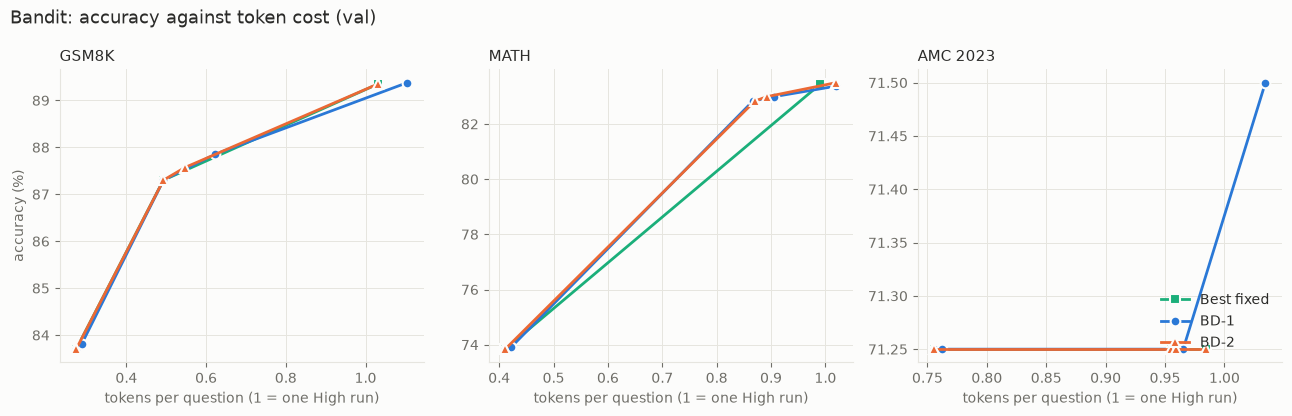

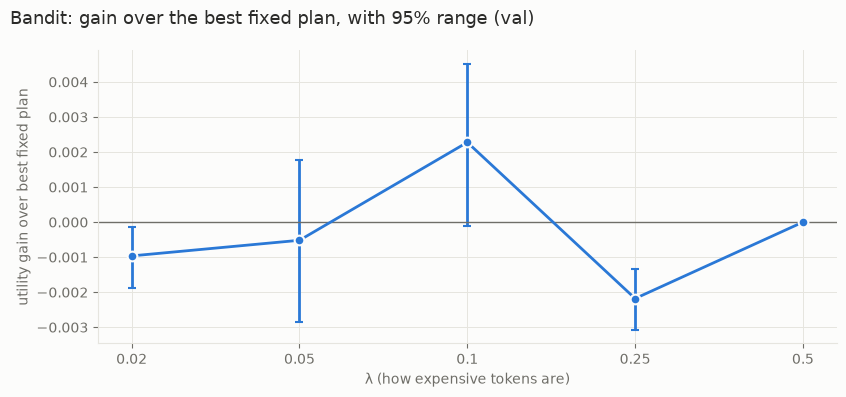

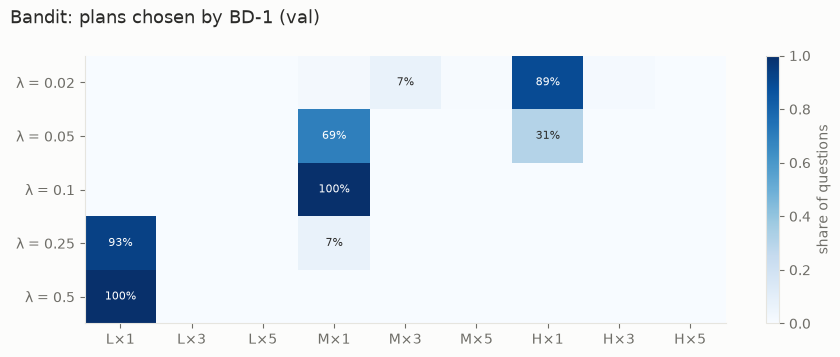

In [13]:
INK, MUTED, GRID, SURFACE = "#2b2b29", "#6f6e68", "#e6e5df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": .7, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 11, "axes.titlelocation": "left", "legend.frameon": False})
FIGURES.mkdir(parents=True, exist_ok=True)
NAMES = {"gsm8k": "GSM8K", "math": "MATH", "amc23": "AMC 2023"}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, dataset in zip(axes, DATASETS):
    part = results[results.dataset == dataset]
    for method, color, marker in [("Best fixed", "#1baf7a", "s"), ("BD-1", "#2a78d6", "o"), ("BD-2", "#eb6834", "^")]:
        line = part[part.method == method].sort_values("tokens")
        ax.plot(line.tokens / C_REF[dataset], 100 * line.accuracy, color=color, marker=marker, lw=2, ms=7, mec=SURFACE, mew=1.5, label=method)
    ax.set_title(NAMES[dataset])
    ax.set_xlabel("tokens per question (1 = one High run)")
axes[0].set_ylabel("accuracy (%)")
axes[-1].legend(loc="lower right")
fig.suptitle(f"Bandit: accuracy against token cost ({REPORT})", x=.01, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES / f"{REPORT}_01_accuracy_vs_cost.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.errorbar(range(len(gains)), gains.gain, yerr=[gains.gain - gains["95% low"], gains["95% high"] - gains.gain], color="#2a78d6", marker="o",
            lw=2, ms=7, mec=SURFACE, mew=1.5, capsize=3, label="BD-1")
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(range(len(LAMBDAS)), LAMBDAS)
ax.set_xlabel("λ (how expensive tokens are)")
ax.set_ylabel("utility gain over best fixed plan")
fig.suptitle(f"Bandit: gain over the best fixed plan, with 95% range ({REPORT})", x=.01, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES / f"{REPORT}_02_gain.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.grid(False)
image = ax.imshow(share.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(PLAN_NAMES)), PLAN_NAMES)
ax.set_yticks(range(len(LAMBDAS)), [f"λ = {lam}" for lam in LAMBDAS])
for r, c in zip(*np.where(share.values >= .05)):
    ax.text(c, r, f"{share.values[r, c]:.0%}", ha="center", va="center", fontsize=8, color="white" if share.values[r, c] > .55 else INK)
fig.colorbar(image, ax=ax, label="share of questions")
fig.suptitle(f"Bandit: plans chosen by BD-1 ({REPORT})", x=.01, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES / f"{REPORT}_03_policies.png", dpi=160)
plt.show()

## Test results

The saved models were evaluated once on the test split. This cell only reads the saved results.

Test utility, all datasets


method,BD-1,BD-2,Best fixed,Oracle
λ,,,,
0.02,0.8352,0.8373,0.8374,0.8833
0.05,0.8120,0.8131,0.8140,0.8554
0.10,0.7804,0.7804,0.7801,0.8198
0.25,0.7117,0.7150,0.7150,0.7398
0.50,0.6228,0.6228,0.6228,0.6333


Test accuracy, all datasets


method,BD-1,BD-2,Best fixed,Oracle
λ,,,,
0.02,0.8561,0.8567,0.8567,0.9050
0.05,0.8490,0.8480,0.8496,0.8969
0.10,0.8467,0.8469,0.8507,0.8840
0.25,0.8080,0.8071,0.8071,0.8591
0.50,0.8071,0.8071,0.8071,0.8356


Per dataset


accuracy                              tokens             \
method           BD-1   BD-2 Best fixed Oracle       BD-1       BD-2   
dataset λ                                                              
amc23   0.02    0.662  0.662      0.662  0.797  16004.900  16004.900   
        0.05    0.675  0.672      0.662  0.761  15492.385  15390.185   
        0.10    0.675  0.675      0.675  0.727  15270.725  15270.725   
        0.25    0.612  0.612      0.612  0.675  10782.588  10782.588   
        0.50    0.612  0.612      0.612  0.675  10782.588  10782.588   
gsm8k   0.02    0.910  0.910      0.910  0.940   6971.425   6382.890   
        0.05    0.899  0.898      0.897  0.938   3946.214   3496.183   
        0.10    0.897  0.897      0.897  0.933   3190.745   3190.745   
        0.25    0.868  0.867      0.867  0.918   1958.544   1827.248   
        0.50    0.867  0.867      0.867  0.891   1827.358   1827.248   
math    0.02    0.823  0.824      0.823  0.878   9165.284   8452.575   
        0.05    0.816  0.815      0.823  0.868   7680.323   7551.048   
        0.10    0.813  0.813      0.823  0.848   7332.102   7363.180   
        0.25    0.765  0.764      0.764  0.815   3737.434   3596.581   
        0.50    0.764  0.764      0.764  0.791   3597.902   3596.581   

                                    
method       Best fixed     Oracle  
dataset λ                           
amc23   0.02  16004.900  40229.788  
        0.05  16004.900  24955.312  
        0.10  15270.725  17759.238  
        0.25  10782.588  11816.838  
        0.50  10782.588  11816.838  
gsm8k   0.02   6382.890   4306.604  
        0.05   3190.745   3686.766  
        0.10   3190.745   3209.379  
        0.25   1827.248   2581.310  
        0.50   1827.248   2007.134  
math    0.02   8369.075  11195.184  
        0.05   8369.075   8819.046  
        0.10   8369.075   6377.615  
        0.25   3596.581   4584.988  
        0.50   3596.581   3945.800

BD-1 gain over the best fixed plan


,λ,gain,95% low,95% high,clear gain?
0,0.02,-0.0022,-0.0033,-0.0010,clear loss
1,0.05,-0.0020,-0.0051,0.0015,no
2,0.10,0.0003,-0.0024,0.0028,no
3,0.25,-0.0032,-0.0046,-0.0019,clear loss
4,0.50,-0.0000,-0.0001,0.0000,no


Share of questions per plan (BD-1)


,L×1,L×3,L×5,M×1,M×3,M×5,H×1,H×3,H×5
λ=0.02,0.000,0.0,0.0,0.022,0.079,0.01,0.874,0.015,0.0
λ=0.05,0.000,0.0,0.0,0.665,0.000,0.00,0.334,0.000,0.0
λ=0.1,0.002,0.0,0.0,0.997,0.000,0.00,0.001,0.000,0.0
λ=0.25,0.908,0.0,0.0,0.092,0.000,0.00,0.000,0.000,0.0
λ=0.5,0.999,0.0,0.0,0.001,0.000,0.00,0.000,0.000,0.0


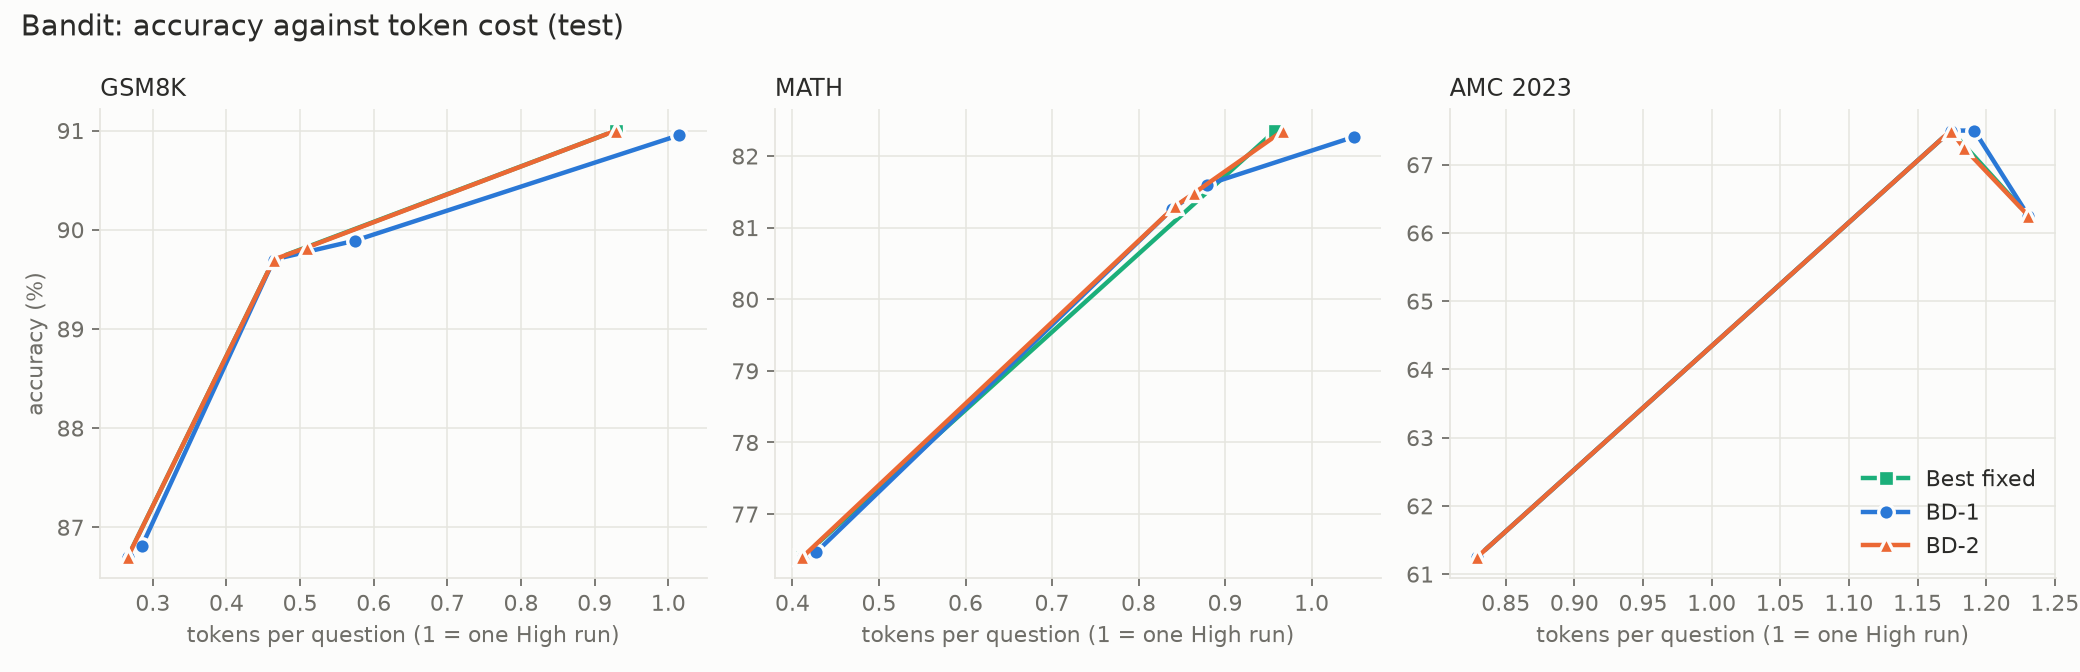

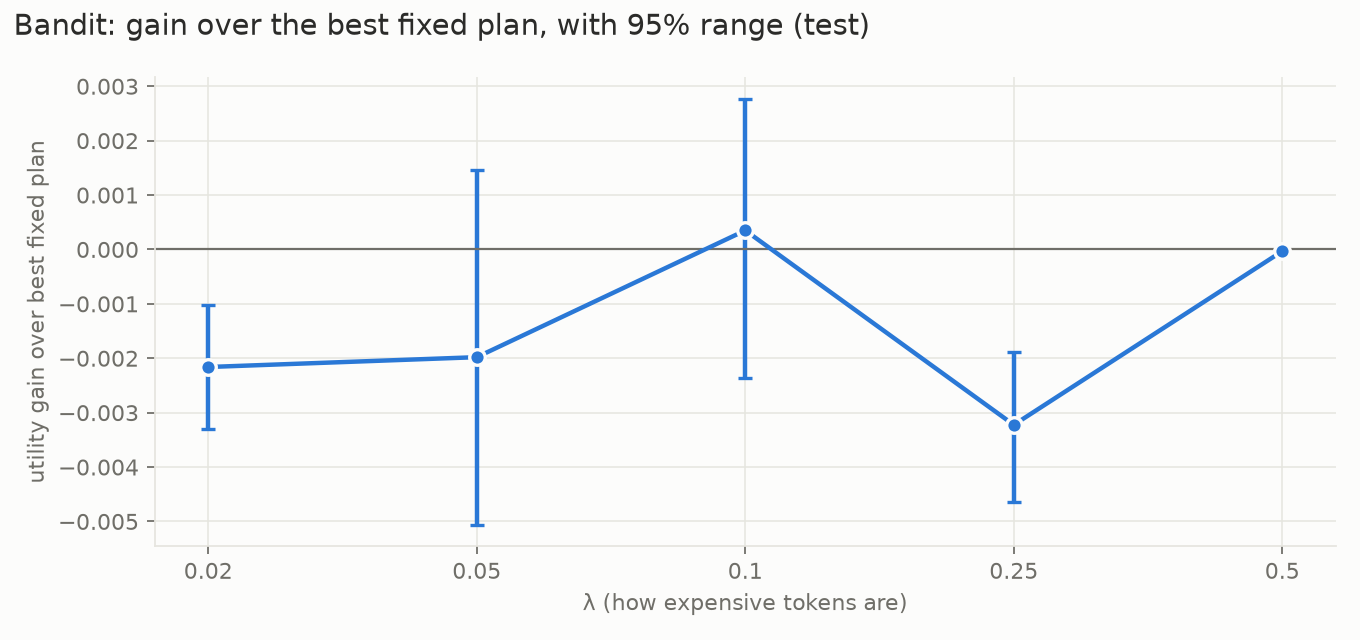

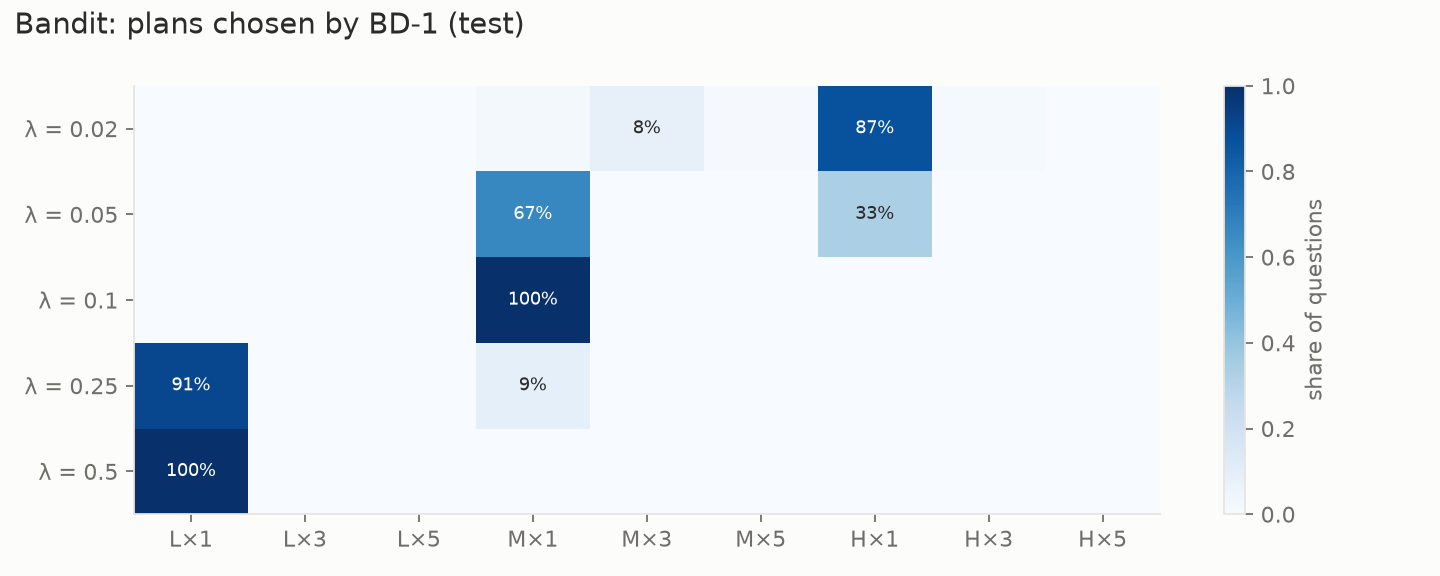

In [14]:
from IPython.display import Image, display
import pandas as pd
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "controller_data").is_dir())
OUT, FIG = ROOT / "rl_training/outputs/bandit", ROOT / "figures/bandit"
results = pd.read_csv(OUT / "test_results.csv")
for value in ("utility", "accuracy"):
    print(f"Test {value}, all datasets")
    display(results[results.dataset == "all (weighted)"].pivot(index="λ", columns="method", values=value)[["BD-1", "BD-2", "Best fixed", "Oracle"]].round(4))
print("Per dataset")
display(results[results.dataset != "all (weighted)"].pivot_table(index=["dataset", "λ"], columns="method", values=["accuracy", "tokens"]).round(3))
print("BD-1 gain over the best fixed plan")
display(pd.read_csv(OUT / "test_gain.csv").round(4))
print("Share of questions per plan (BD-1)")
display(pd.read_csv(OUT / "test_policies.csv", index_col=0).round(3))
for path in sorted(FIG.glob("test_*.png")):
    display(Image(filename=str(path), width=900))
